# spec-trait Evaluation

Analysis of runtime performance, compile time, and binary size for `spec!`/`when` vs alternatives:
- **spec**: compile-time specialization via `spec!`/`when` macros
- **dyn**: trait object dynamic dispatch
- **enum**: enum-based dispatch
- **generic**: generic fallback (no specialization)
- **runtime_typeid**: `TypeId`-based runtime branching

## Examples
| # | Operation | Key specialization |
|---|-----------|--------------------|
| ex01 | Histogram | u8 array[256] vs HashMap |
| ex02 | Set intersection | u8 bitmap[256] vs HashSet |
| ex03 | Contains search | u8 memchr SIMD |
| ex04 | Sort | u8 counting sort |
| ex05 | Distinct count | u8 bitmap[256] vs HashSet |
| ex06 | Bulk serialize | u8 zero-copy |
| ex07 | Dedup | u8 bitmap vs HashSet |
| ex08 | Count value | u8 memchr_iter vs filter |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.1)
RESULTS = Path("../results")

APPROACH_ORDER = ["spec", "enum", "runtime_typeid", "naive"]
APPROACH_COLORS = {
    "spec": "#2ca02c",
    "enum": "#1f77b4",
    "runtime_typeid": "#d62728",
    "naive": "#9467bd",
}

## 1. Runtime Performance

In [2]:
rt = pd.read_csv(RESULTS / "runtime_tmp.csv")
rt["size"] = pd.to_numeric(rt["size"], errors="coerce")
rt = rt.dropna(subset=["size", "median_ns"])
rt["median_us"] = rt["median_ns"] / 1000.0 # from nanoseconds to microseconds

examples = sorted(rt["example"].unique())
n_ex = len(examples)
rt.head()

,example,operation,group,approach,size,mean_ns,mean_se_ns,mean_ci_lower_ns,mean_ci_upper_ns,median_ns,median_se_ns,median_ci_lower_ns,median_ci_upper_ns,slope_ns,slope_se_ns,slope_ci_lower_ns,slope_ci_upper_ns,std_dev_ns,median_abs_dev_ns,median_us
0,ex06,dedup,ex06_dedup,enum,1024,4064.629353,6.449273,4051.149694,4076.262897,4068.374410,7.801870,4053.226702,4081.086480,4074.129708,4.913476,4064.446356,4083.578179,21.481078,20.340341,4.068374
1,ex06,dedup,ex06_dedup,enum,128,547.281362,1.945371,543.265120,550.848360,548.374137,1.886293,543.289908,551.450640,551.544899,1.445676,548.145640,553.768181,6.498637,5.071374,0.548374
2,ex06,dedup,ex06_dedup,enum,16,101.960440,0.237245,101.487685,102.415975,101.872040,0.280795,101.475588,102.682913,102.037668,0.274853,101.587897,102.635023,0.791339,0.722168,0.101872
3,ex06,dedup,ex06_dedup,enum,2048,8079.916529,15.163509,8049.149198,8108.082591,8094.155710,22.626264,8023.496204,8122.559571,8090.713325,19.947007,8045.155508,8121.200890,50.501880,42.479328,8.094156
4,ex06,dedup,ex06_dedup,enum,256,1053.038231,2.237445,1048.693521,1057.388790,1053.852292,3.248186,1047.040990,1058.242216,1051.947176,3.176878,1045.742351,1057.943124,7.443173,6.639977,1.053852


### Perche' usiamo la mediana e dividiamo per 1000?

Usiamo `median_ns` perche' la **mediana** e' piu' robusta della media rispetto a outlier e rumore sperimentale. Nei benchmark alcune misure possono essere disturbate da effetti esterni come scheduling del sistema operativo, cache, turbo boost o processi in background: la mediana rappresenta meglio il **tempo tipico** osservato.

La divisione per `1000.0` serve solo a cambiare unita' di misura: i dati nel CSV sono in **nanosecondi (`ns`)**, mentre nei grafici vogliamo mostrare **microsecondi (`µs`)** per avere valori piu' leggibili.

$$1\,\mu s = 1000\,ns$$

Quindi:

- `median_ns` = tempo mediano in nanosecondi
- `median_us = median_ns / 1000.0` = stesso valore espresso in microsecondi

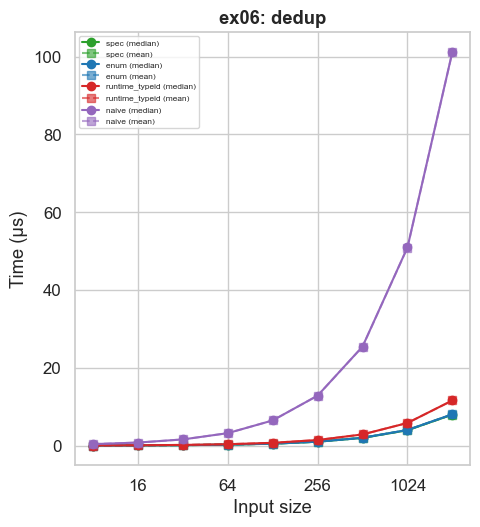

In [3]:

# Mean vs Median comparison — one subplot per example, two lines per approach
has_mean = "mean_ns" in rt.columns

if has_mean:
    rt["mean_us"] = rt["mean_ns"] / 1000.0

    fig, axes = plt.subplots(2, (n_ex + 1) // 2, figsize=(5 * ((n_ex + 1) // 2), 10), sharey=False)
    axes = axes.flatten()

    for idx, ex in enumerate(examples):
        ax = axes[idx]
        sub = rt[rt["example"] == ex]
        op = sub["operation"].iloc[0]
        for approach in APPROACH_ORDER:
            d = sub[sub["approach"] == approach].sort_values("size")
            if d.empty:
                continue
            color = APPROACH_COLORS.get(approach, "gray")
            ax.plot(d["size"], d["median_us"], marker="o", linestyle="-",
                    label=f"{approach} (median)", color=color)
            ax.plot(d["size"], d["mean_us"], marker="s", linestyle="--",
                    label=f"{approach} (mean)", color=color, alpha=0.6)
        ax.set_title(f"{ex}: {op}", fontweight="bold")
        ax.set_xlabel("Input size")
        ax.set_ylabel("Time (µs)")
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
        ax.legend(fontsize=6)

    for idx in range(n_ex, len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.savefig(RESULTS / "mean_vs_median.pdf", bbox_inches="tight")
    plt.show()
else:
    print("mean_ns column not found — only median is available.")


In [ ]:
fig, axes = plt.subplots(2, (n_ex + 1) // 2, figsize=(5 * ((n_ex + 1) // 2), 10), sharey=False)
axes = axes.flatten()

for idx, ex in enumerate(examples):
    ax = axes[idx]
    sub = rt[rt["example"] == ex]
    op = sub["operation"].iloc[0]
    for approach in APPROACH_ORDER:
        d = sub[sub["approach"] == approach].sort_values("size")
        if d.empty:
            continue
        ax.plot(d["size"], d["median_us"], marker="o", label=approach,
                color=APPROACH_COLORS.get(approach, "gray"))
    ax.set_title(f"{ex}: {op}", fontweight="bold")
    ax.set_xlabel("Input size")
    ax.set_ylabel("Median time (\u00b5s)")
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.legend(fontsize=8)

for idx in range(n_ex, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig(RESULTS / "runtime_all.pdf", bbox_inches="tight")
plt.show()

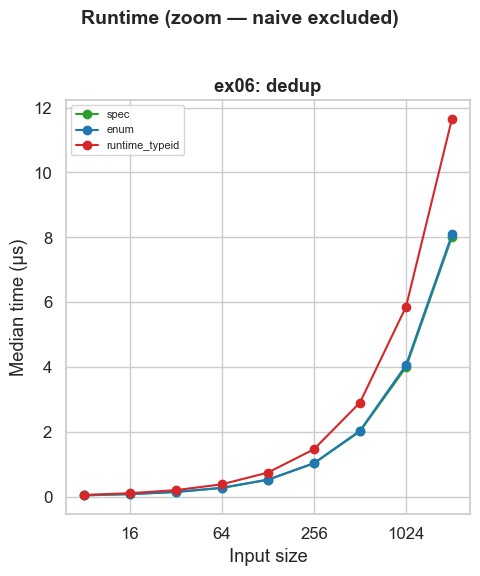

In [4]:

# Zoomed-in runtime plot — excludes 'naive' to reveal differences among fast approaches
ZOOM_APPROACHES = [a for a in APPROACH_ORDER if a != "naive"]

fig, axes = plt.subplots(2, (n_ex + 1) // 2, figsize=(5 * ((n_ex + 1) // 2), 10), sharey=False)
axes = axes.flatten()

for idx, ex in enumerate(examples):
    ax = axes[idx]
    sub = rt[rt["example"] == ex]
    op = sub["operation"].iloc[0]
    for approach in ZOOM_APPROACHES:
        d = sub[sub["approach"] == approach].sort_values("size")
        if d.empty:
            continue
        ax.plot(d["size"], d["median_us"], marker="o", label=approach,
                color=APPROACH_COLORS.get(approach, "gray"))
    ax.set_title(f"{ex}: {op}", fontweight="bold")
    ax.set_xlabel("Input size")
    ax.set_ylabel("Median time (µs)")
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.legend(fontsize=8)

for idx in range(n_ex, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Runtime (zoom — naive excluded)", fontweight="bold", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(RESULTS / "runtime_zoom.pdf", bbox_inches="tight")
plt.show()


### Speedup of `spec` over each alternative (at largest size)

In [5]:
largest = rt.groupby(["example", "approach"]).apply(
    lambda g: g.loc[g["size"].idxmax()]
).reset_index(drop=True)

spec_times = largest[largest["approach"] == "spec"][["example", "median_ns"]].rename(
    columns={"median_ns": "spec_ns"}
)
merged = largest.merge(spec_times, on="example")
merged["speedup_vs_spec"] = merged["median_ns"] / merged["spec_ns"]

pivot = merged.pivot_table(index="example", columns="approach", values="speedup_vs_spec")
pivot = pivot[[c for c in APPROACH_ORDER if c in pivot.columns]]
pivot.style.format("{:.2f}x").background_gradient(cmap="RdYlGn", axis=None)

/var/folders/85/w1f_3bln5rzbljrg0v33t7880000gn/T/ipykernel_31985/1433551797.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  largest = rt.groupby(["example", "approach"]).apply(


approach,spec,enum,runtime_typeid,naive
example,,,,
ex06,1.00x,1.01x,1.45x,12.62x


### Runtime with 95% Confidence Intervals

In [ ]:
# Runtime plots with 95% CI error bands (from mean_ci_lower_ns / mean_ci_upper_ns)
has_ci = "mean_ci_lower_ns" in rt.columns and "mean_ci_upper_ns" in rt.columns

if has_ci:
    rt["mean_us"] = rt["mean_ns"] / 1000.0
    rt["ci_lower_us"] = rt["mean_ci_lower_ns"] / 1000.0
    rt["ci_upper_us"] = rt["mean_ci_upper_ns"] / 1000.0

    fig, axes = plt.subplots(2, (n_ex + 1) // 2, figsize=(5 * ((n_ex + 1) // 2), 10), sharey=False)
    axes = axes.flatten()

    for idx, ex in enumerate(examples):
        ax = axes[idx]
        sub = rt[rt["example"] == ex]
        op = sub["operation"].iloc[0]
        for approach in APPROACH_ORDER:
            d = sub[sub["approach"] == approach].sort_values("size")
            if d.empty:
                continue
            color = APPROACH_COLORS.get(approach, "gray")
            ax.plot(d["size"], d["mean_us"], marker="o", label=approach, color=color)
            ax.fill_between(d["size"], d["ci_lower_us"], d["ci_upper_us"], alpha=0.15, color=color)
        ax.set_title(f"{ex}: {op}", fontweight="bold")
        ax.set_xlabel("Input size")
        ax.set_ylabel("Mean time ± 95% CI (µs)")
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
        ax.legend(fontsize=8)

    for idx in range(n_ex, len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.savefig(RESULTS / "runtime_ci.pdf", bbox_inches="tight")
    plt.show()
else:
    print("CI columns not found in runtime.csv — re-run collect_metrics.py with the updated script.")

### Measurement Stability (Coefficient of Variation)

The coefficient of variation (CV = std_dev / mean) shows how noisy each measurement is.
Lower is better: CV < 1% is excellent, 1–5% is acceptable, > 5% suggests instability.

In [ ]:
# Heatmap of coefficient of variation (CV%) at the largest input size
has_std = "std_dev_ns" in rt.columns

if has_std:
    largest_full = rt.groupby(["example", "approach"]).apply(
        lambda g: g.loc[g["size"].idxmax()]
    ).reset_index(drop=True)
    largest_full["cv_pct"] = (largest_full["std_dev_ns"] / largest_full["mean_ns"]) * 100.0

    cv_pivot = largest_full.pivot_table(index="example", columns="approach", values="cv_pct")
    cv_pivot = cv_pivot[[c for c in APPROACH_ORDER if c in cv_pivot.columns]]

    fig, ax = plt.subplots(figsize=(8, max(3, len(cv_pivot) * 0.5)))
    sns.heatmap(cv_pivot, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax,
                cbar_kws={"label": "CV (%)"}, linewidths=0.5)
    ax.set_title("Coefficient of Variation (%) at Largest Size", fontweight="bold")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.savefig(RESULTS / "cv_heatmap.pdf", bbox_inches="tight")
    plt.show()
else:
    print("std_dev_ns column not found — re-run collect_metrics.py with the updated script.")

### Slope vs Mean Estimate

Criterion computes a *slope* via linear regression over (iterations, time), which is more robust than the arithmetic mean against outliers.
Large divergence between slope and mean suggests measurement noise or non-linear scaling.

In [ ]:
# Scatter: slope_ns vs mean_ns — points near the diagonal = stable measurements
has_slope = "slope_ns" in rt.columns

if has_slope:
    rt_valid = rt.dropna(subset=["slope_ns", "mean_ns"])

    fig, ax = plt.subplots(figsize=(7, 7))
    for approach in APPROACH_ORDER:
        d = rt_valid[rt_valid["approach"] == approach]
        if d.empty:
            continue
        ax.scatter(d["mean_ns"], d["slope_ns"], label=approach, alpha=0.6, s=20,
                   color=APPROACH_COLORS.get(approach, "gray"))

    # Reference diagonal (slope == mean)
    lo = min(rt_valid["mean_ns"].min(), rt_valid["slope_ns"].min())
    hi = max(rt_valid["mean_ns"].max(), rt_valid["slope_ns"].max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8, alpha=0.5, label="slope = mean")

    ax.set_xlabel("Mean (ns)")
    ax.set_ylabel("Slope (ns)")
    ax.set_title("Slope vs Mean — closer to diagonal = more stable", fontweight="bold")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(RESULTS / "slope_vs_mean.pdf", bbox_inches="tight")
    plt.show()

    # Divergence table: |slope - mean| / mean at largest size
    if has_std:  # reuses largest_full from CV cell
        largest_full["slope_mean_pct"] = (
            (largest_full["slope_ns"] - largest_full["mean_ns"]).abs() / largest_full["mean_ns"] * 100
        )
        div_pivot = largest_full.pivot_table(index="example", columns="approach", values="slope_mean_pct")
        div_pivot = div_pivot[[c for c in APPROACH_ORDER if c in div_pivot.columns]]
        display(div_pivot.style.format("{:.3f}%")
                .background_gradient(cmap="YlOrRd", axis=None)
                .set_caption("|slope − mean| / mean (%) at largest size"))
else:
    print("slope_ns column not found — re-run collect_metrics.py with the updated script.")

## 2. Compile Time

In [ ]:
bt = pd.read_csv(RESULTS / "build_time.csv")
bt_avg = bt.groupby(["example", "variant"])["build_time_secs"].mean().reset_index()
bt_avg.columns = ["example", "approach", "mean_build_secs"]

fig, ax = plt.subplots(figsize=(10, 5))
bt_pivot = bt_avg.pivot(index="example", columns="approach", values="mean_build_secs")
bt_pivot = bt_pivot[[c for c in APPROACH_ORDER if c in bt_pivot.columns]]
bt_pivot.plot(kind="bar", ax=ax, color=[APPROACH_COLORS.get(c, "gray") for c in bt_pivot.columns])
ax.set_ylabel("Mean build time (s)")
ax.set_title("Compile Time per Example & Approach")
ax.legend(title="Approach", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS / "build_time.pdf", bbox_inches="tight")
plt.show()

## 3. Binary Size

In [ ]:
bs = pd.read_csv(RESULTS / "binary_size.csv")
bs.columns = ["example", "approach", "binary_size_bytes", "stripped_size_bytes"]
bs["size_kb"] = bs["binary_size_bytes"] / 1024.0

fig, ax = plt.subplots(figsize=(10, 5))
bs_pivot = bs.pivot(index="example", columns="approach", values="size_kb")
bs_pivot = bs_pivot[[c for c in APPROACH_ORDER if c in bs_pivot.columns]]
bs_pivot.plot(kind="bar", ax=ax, color=[APPROACH_COLORS.get(c, "gray") for c in bs_pivot.columns])
ax.set_ylabel("Artifact size (KB)")
ax.set_title("Binary Size per Example & Approach")
ax.legend(title="Approach", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS / "binary_size.pdf", bbox_inches="tight")
plt.show()

## 4. Summary Table

In [ ]:
# Combine all metrics into a single summary
summary_parts = []

# Runtime speedup at largest size
if 'pivot' in dir():
    rt_summary = pivot.mean().rename("mean_speedup_vs_spec")
    summary_parts.append(rt_summary)

# Build time overhead vs spec
if 'bt_avg' in dir():
    spec_bt = bt_avg[bt_avg["approach"] == "spec"][["example", "mean_build_secs"]].rename(
        columns={"mean_build_secs": "spec_build"}
    )
    bt_merged = bt_avg.merge(spec_bt, on="example")
    bt_merged["build_ratio"] = bt_merged["mean_build_secs"] / bt_merged["spec_build"]
    bt_ratio = bt_merged.groupby("approach")["build_ratio"].mean()
    summary_parts.append(bt_ratio.rename("mean_build_ratio_vs_spec"))

# Binary size overhead vs spec
if 'bs' in dir():
    spec_bs = bs[bs["approach"] == "spec"][["example", "binary_size_bytes"]].rename(
        columns={"binary_size_bytes": "spec_size"}
    )
    bs_merged = bs.merge(spec_bs, on="example")
    bs_merged["size_ratio"] = bs_merged["binary_size_bytes"] / bs_merged["spec_size"]
    bs_ratio = bs_merged.groupby("approach")["size_ratio"].mean()
    summary_parts.append(bs_ratio.rename("mean_size_ratio_vs_spec"))

if summary_parts:
    summary = pd.concat(summary_parts, axis=1)
    summary = summary.loc[[a for a in APPROACH_ORDER if a in summary.index]]
    summary.style.format("{:.2f}").background_gradient(cmap="RdYlGn_r", axis=0)